# Оценка радиусов объектов

### Фиксация параметров из первого исследования:
- **Модель внимания**: UNISAL (оригинальное разрешение)
- **Порог отсечения**: топ-5% внимания
- **Параметры DBSCAN**: eps = 4.0 px, min_samples = 5
- **Центр кластера**: геометрический центр маски

Во втором исследовании сравниваем три способа оценки характерного размера объектов:
- **R_gyr**: радиус гирации (среднеквадратичное отклонение точек от центра)
- **R_disk**: радиус эквивалентного диска (D_disk = sqrt(A / pi), R_disk = D_disk / 2)
- **R_max**: максимальное расстояние от центра до крайней точки

In [1]:
import sys
import math
from pathlib import Path
import cv2
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN
from IPython.display import display

sys.path.append("..")

from src.paths import BASE_DIR
from src.geometry import ViewingGeometry
from src.utils.converter import ImageConverter
from src.keypoints.saliency.unisal_model import load_unisal_model, predict_unisal_attention

plt.rcParams['figure.figsize'] = (22, 10)
plt.rcParams['font.size'] = 11

geometry = ViewingGeometry(view_dist_mm=600.0, l_min=0.1, l_max=300.0)
converter = ImageConverter(L_MIN=geometry.l_min, L_MAX=geometry.l_max)

m_unisal = load_unisal_model(device="cpu")

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}
EXAMPLE_IMAGES = sorted([
    p for p in (BASE_DIR / "examples").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

torch device set to: cpu


c:\Users\Misha_Savinov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4223.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


## Визуализация радиусов R_gyr, R_disk и R_max

In [2]:
def run_experiment_3(
    img_path_input,
    top_pct: float = 5.0,
    eps: float = 4.0,
    min_samples: int = 10
):
    img_path = Path(img_path_input)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"Ошибка загрузки файла: {img_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    print(f"Изображение: {img_path.name} | Разрешение: {w}x{h} px | Модель: UNISAL (оригинал)")
    print(f"Параметры: топ-{top_pct}% внимания, eps={eps} px, геометрический центр\n")
    
    heat_unisal_orig = predict_unisal_attention(img_rgb, m_unisal, resize=False)
    q_th = float(np.percentile(heat_unisal_orig, 100 - top_pct))
    ys, xs = np.where(heat_unisal_orig >= q_th)
    
    if len(xs) == 0:
        print("Кластеры не найдены.\n")
        return
        
    points_full = np.column_stack([xs, ys])
    stride = max(1, int(np.ceil(len(xs) / 20000)))
    points = points_full[::stride]
    eff_min_samples = max(5, int(min_samples / stride))
    
    db = DBSCAN(eps=eps, min_samples=eff_min_samples).fit(points)
    labels = db.labels_
    unique_labels = [k for k in sorted(list(set(labels))) if k != -1]
    
    if not unique_labels:
        print("Значимых кластеров не выделено (все точки классифицированы как шум).\n")
        return
        
    cluster_records = []
    rad_per_px = geometry.rad_per_px(w)
    
    for k in unique_labels:
        mask = (labels == k)
        c_pts = points[mask]
        n_pts = len(c_pts) * stride
        
        cx = float(np.mean(c_pts[:, 0]))
        cy = float(np.mean(c_pts[:, 1]))
        
        diff = c_pts - np.array([cx, cy])
        dists = np.sqrt(np.sum(diff ** 2, axis=1))
        
        r_gyr = float(np.sqrt(np.mean(dists ** 2)))
        d_gyr = 2.0 * r_gyr
        
        d_disk = float(math.sqrt(n_pts / math.pi))
        r_disk = d_disk / 2.0
        
        r_max = float(np.max(dists))
        d_max = 2.0 * r_max
        
        cluster_records.append({
            'label': k,
            'pts': c_pts,
            'size': n_pts,
            'center': (cx, cy),
            'r_gyr': r_gyr,
            'd_gyr': d_gyr,
            'r_disk': r_disk,
            'd_disk': d_disk,
            'r_max': r_max,
            'd_max': d_max
        })
        
    cluster_records.sort(key=lambda c: c['size'], reverse=True)
    cmap_clusters = mpl.colormaps['tab20']
    
    fig_configs = [
        ("Радиус гирации R_gyr", 'r_gyr', 'cyan', '-', 'Окружность R_gyr'),
        ("Диск D_disk = sqrt(A/pi), R = D/2", 'r_disk', 'magenta', '--', 'Окружность R_disk (D=sqrt(A/pi))'),
        ("Радиус до дальней точки R_max", 'r_max', 'gold', '-.', 'Окружность R_max')
    ]
    
    for title, r_key, circ_color, circ_ls, circ_lbl in fig_configs:
        fig, ax = plt.subplots(figsize=(16, 9), layout="constrained")
        ax.imshow(img_rgb)
        for rank, cr in enumerate(cluster_records):
            c_pts = cr['pts']
            cx, cy = cr['center']
            r = cr[r_key]
            color = cmap_clusters(cr['label'] % 20)
            
            lbl_pts = f"К{rank+1} ({cr['size']:,} px)" if rank < 6 else None
            ax.scatter(c_pts[:, 0], c_pts[:, 1], color=color, s=12, alpha=0.55, label=lbl_pts)
            
            circle = plt.Circle((cx, cy), r, color=circ_color, fill=False, linewidth=2.4, linestyle=circ_ls)
            ax.add_patch(circle)
            ax.scatter(cx, cy, c=circ_color, edgecolors='black', marker='o', s=55, zorder=6)
            ax.text(cx + 6, cy - 6, f"К{rank+1}", color='white', weight='bold', fontsize=10,
                    bbox=dict(facecolor='black', alpha=0.6, pad=1.5, edgecolor='none'))
                    
        if len(cluster_records) > 6:
            ax.scatter([], [], color='none', label=f"+ еще {len(cluster_records)-6} мелких кл.")
        ax.plot([], [], color=circ_color, linewidth=2.4, linestyle=circ_ls, label=circ_lbl)
        ax.scatter([], [], c=circ_color, edgecolors='black', marker='o', s=55, label='Геометрический центр')
        ax.set_title(f"{img_path.name} | {title} ({len(cluster_records)} кластеров)", fontsize=13)
        ax.axis('off')
        ax.legend(loc='lower right', fontsize=9, framealpha=0.9)
        plt.show()
        plt.close('all')
    
    table_rows = []
    for rank, cr in enumerate(cluster_records):
        cx, cy = cr['center']
        table_rows.append({
            'Объект': f"К{rank+1}",
            'Площадь (px)': cr['size'],
            'Центр (x, y)': f"({cx:.1f}, {cy:.1f})",
            'D_disk (px)': round(cr['d_disk'], 1),
            'D_gyr (px)': round(cr['d_gyr'], 1),
            'D_max (px)': round(cr['d_max'], 1),
            'R_disk (px)': round(cr['r_disk'], 1),
            'R_gyr (px)': round(cr['r_gyr'], 1),
            'R_max (px)': round(cr['r_max'], 1),
            'Угол D_disk (мрад)': round(cr['d_disk'] * rad_per_px * 1000, 2),
            'Угол D_gyr (мрад)': round(cr['d_gyr'] * rad_per_px * 1000, 2),
            'Угол D_max (мрад)': round(cr['d_max'] * rad_per_px * 1000, 2)
        })
        
    df_obj = pd.DataFrame(table_rows)
    print(f'\nРазмеры объектов для {img_path.name}:')
    display(df_obj)
    print()

Изображение: alenyshka.jpg | Разрешение: 1280x770 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



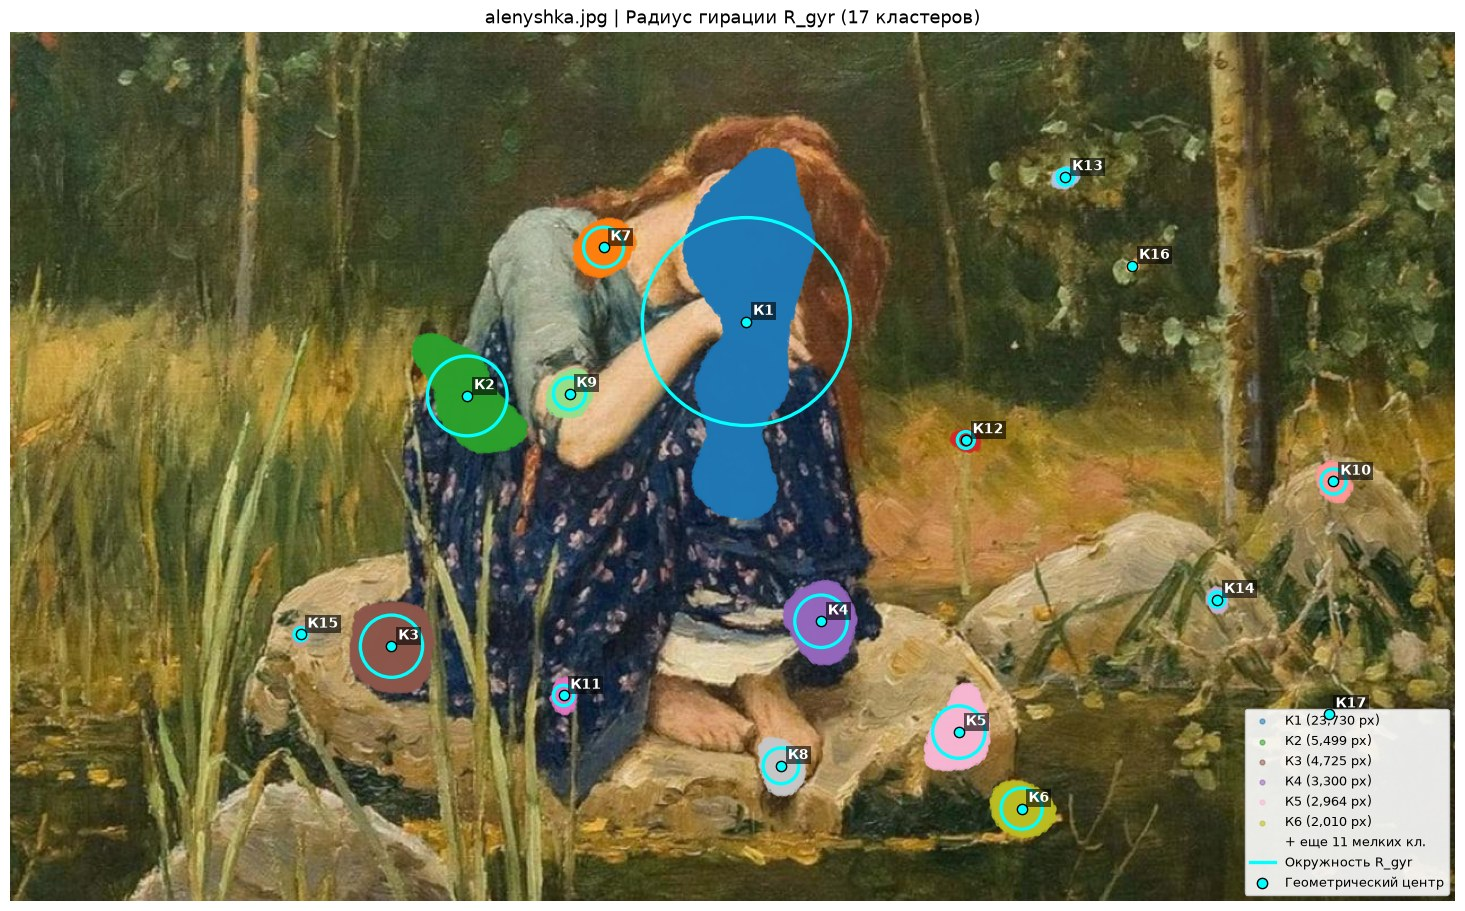

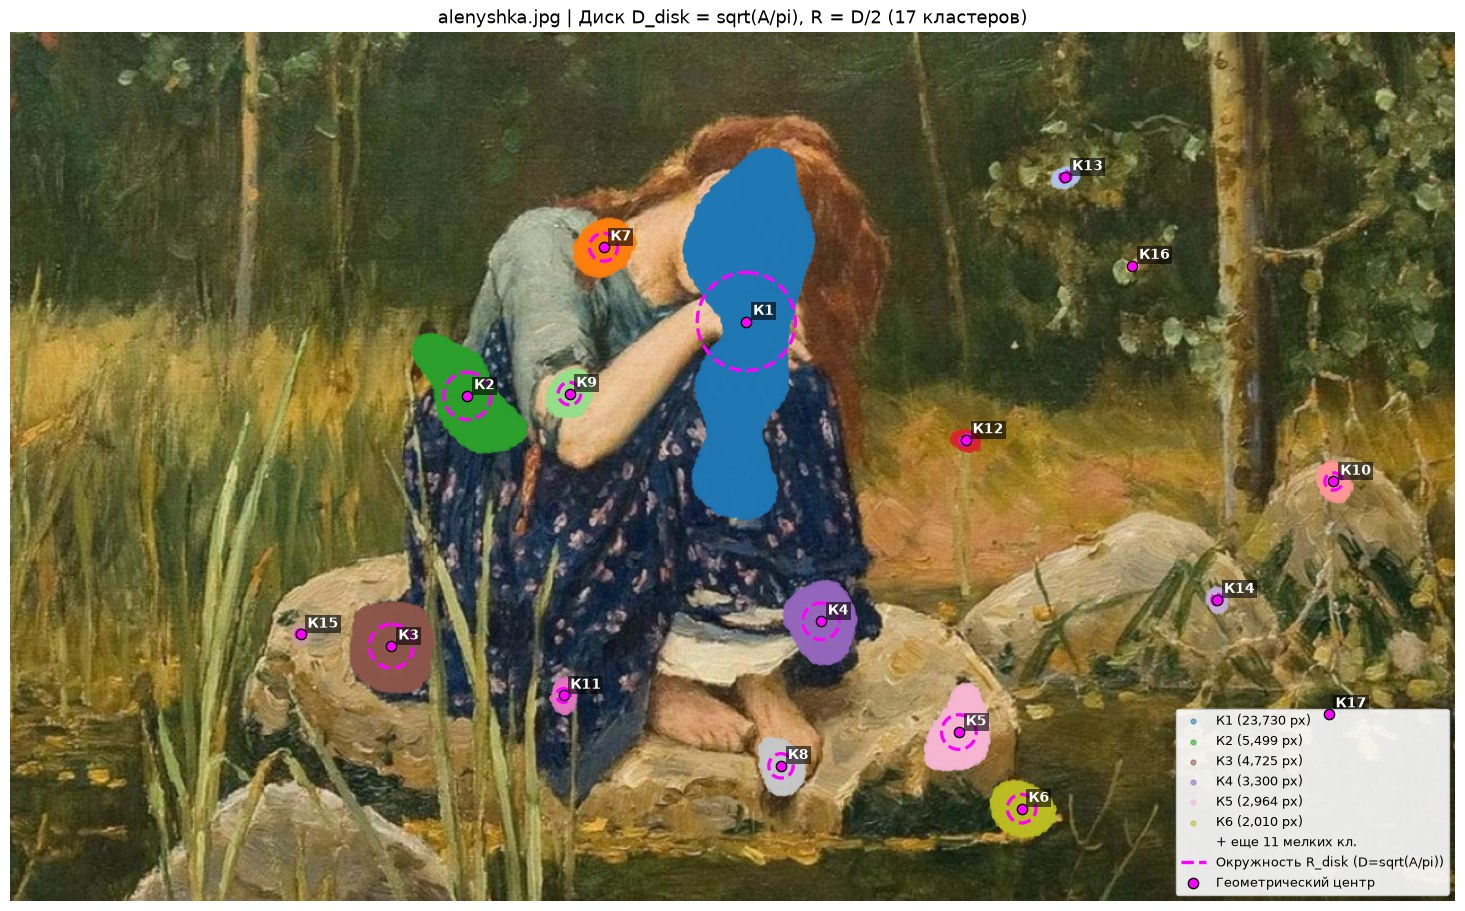

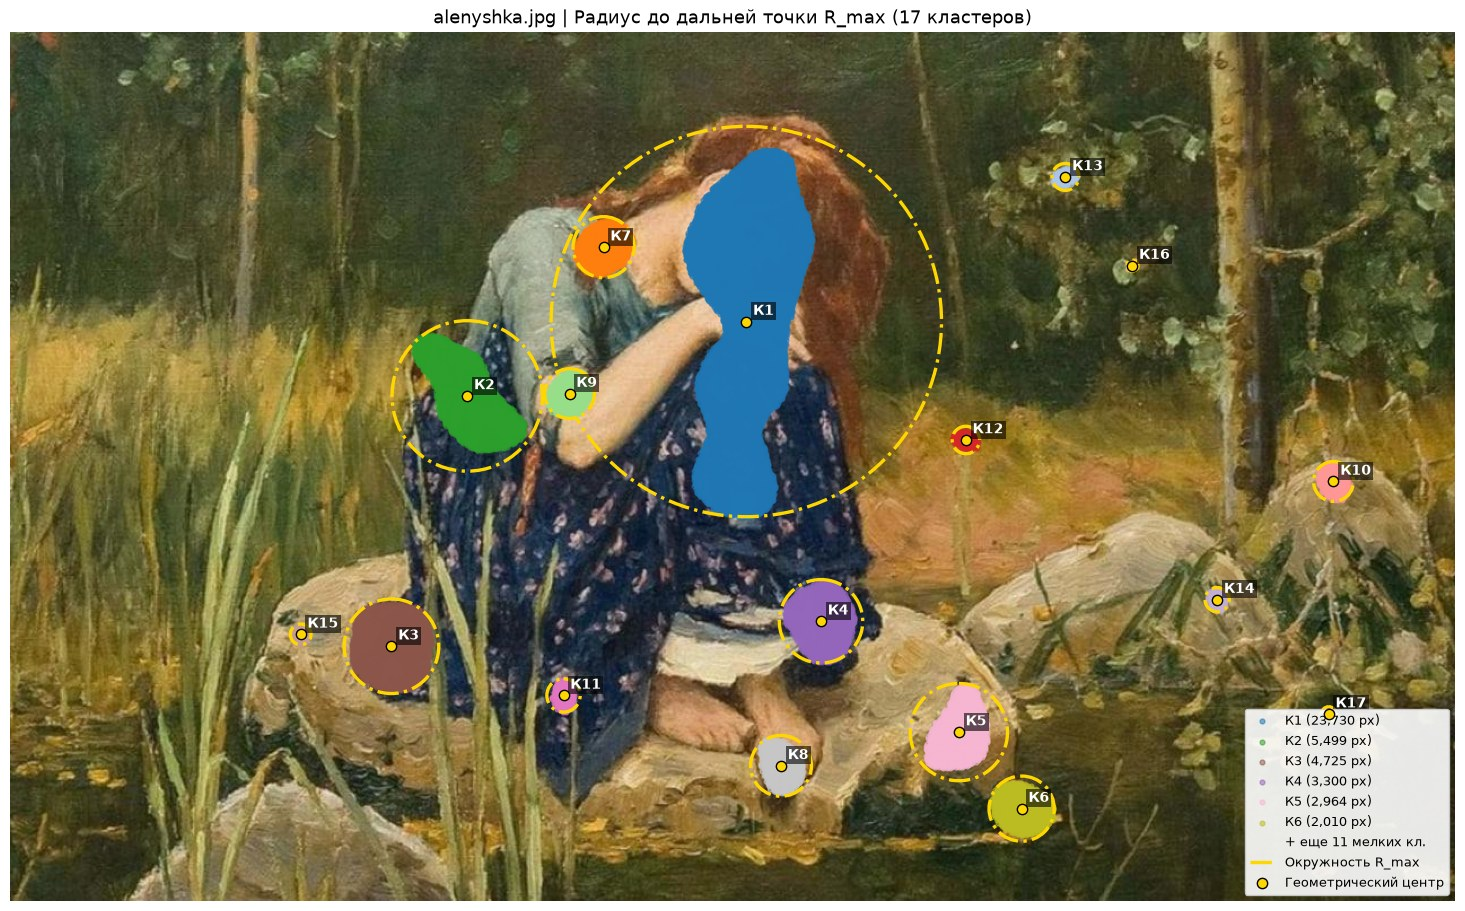


Размеры объектов для alenyshka.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,23730,"(651.7, 256.2)",86.9,184.2,345.8,43.5,92.1,172.9,40.08,84.94,159.47
1,К2,5499,"(404.5, 322.1)",41.8,70.7,133.3,20.9,35.3,66.6,19.30,32.59,61.47
2,К3,4725,"(337.4, 543.8)",38.8,55.2,83.8,19.4,27.6,41.9,17.89,25.44,38.64
3,К4,3300,"(717.8, 521.7)",32.4,46.5,73.9,16.2,23.2,37.0,14.95,21.44,34.09
4,К5,2964,"(840.0, 619.9)",30.7,46.5,86.1,15.4,23.2,43.1,14.17,21.43,39.73
5,К6,2010,"(895.5, 687.7)",25.3,36.3,57.7,12.6,18.2,28.9,11.67,16.76,26.62
6,К7,1932,"(525.3, 190.4)",24.8,35.4,54.1,12.4,17.7,27.0,11.44,16.34,24.94
7,К8,1464,"(682.4, 649.8)",21.6,31.6,53.9,10.8,15.8,26.9,9.96,14.56,24.86
8,К9,1242,"(495.1, 320.1)",19.9,28.5,44.1,9.9,14.2,22.0,9.17,13.13,20.33
9,К10,735,"(1171.8, 397.9)",15.3,22.2,35.3,7.6,11.1,17.6,7.05,10.23,16.28



Изображение: br_joi.jpg | Разрешение: 1500x999 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



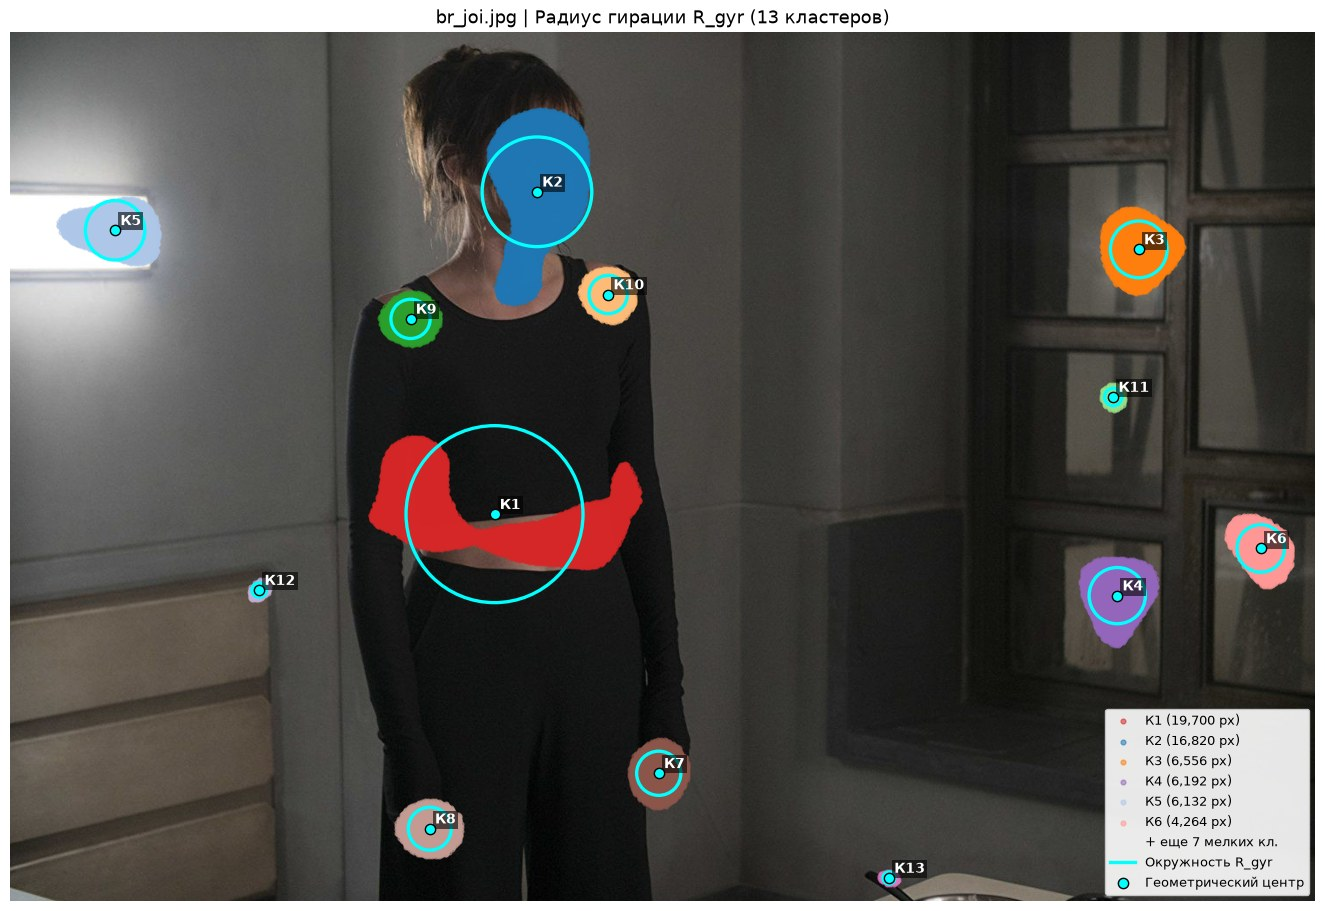

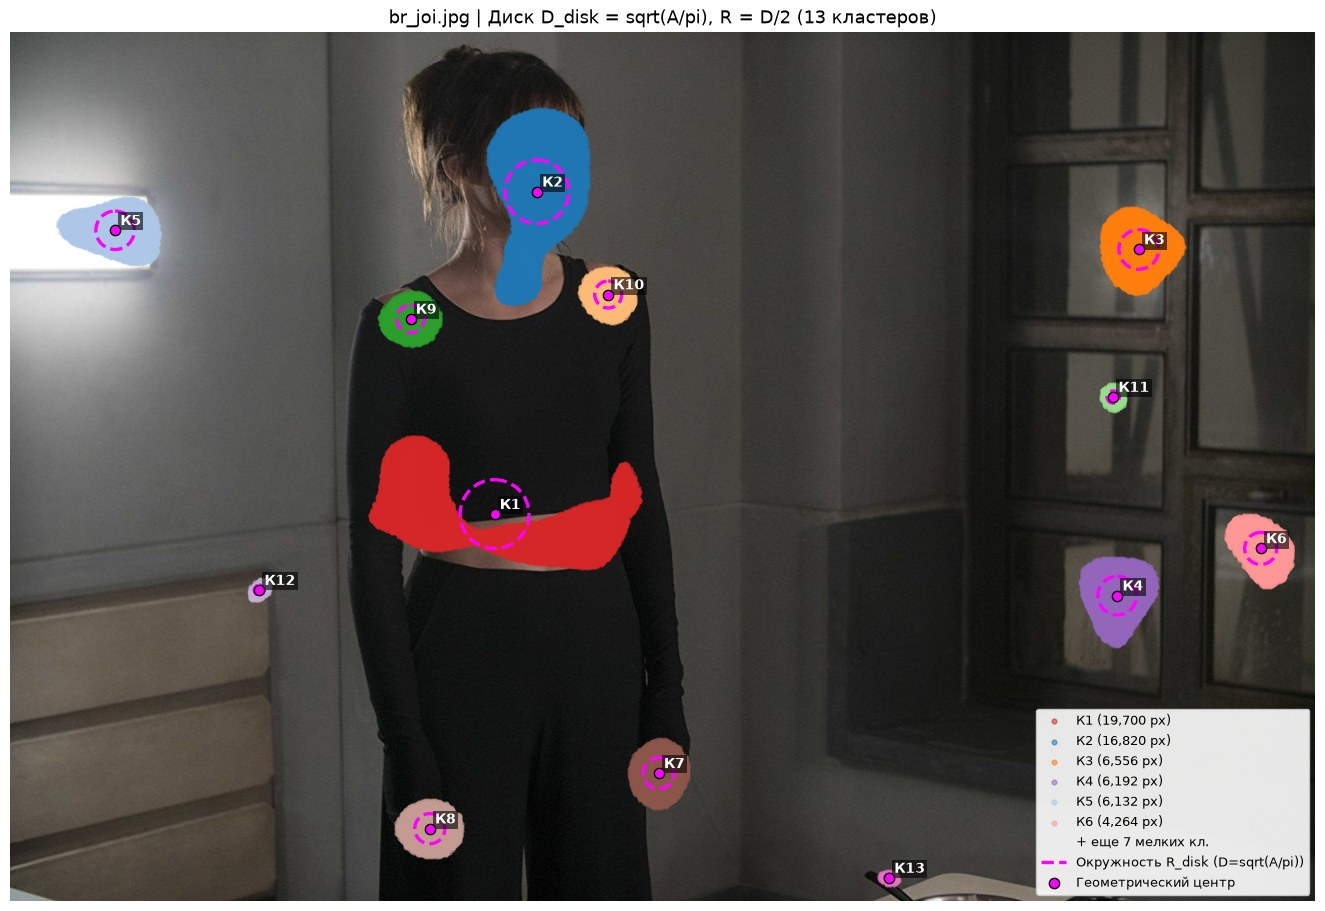

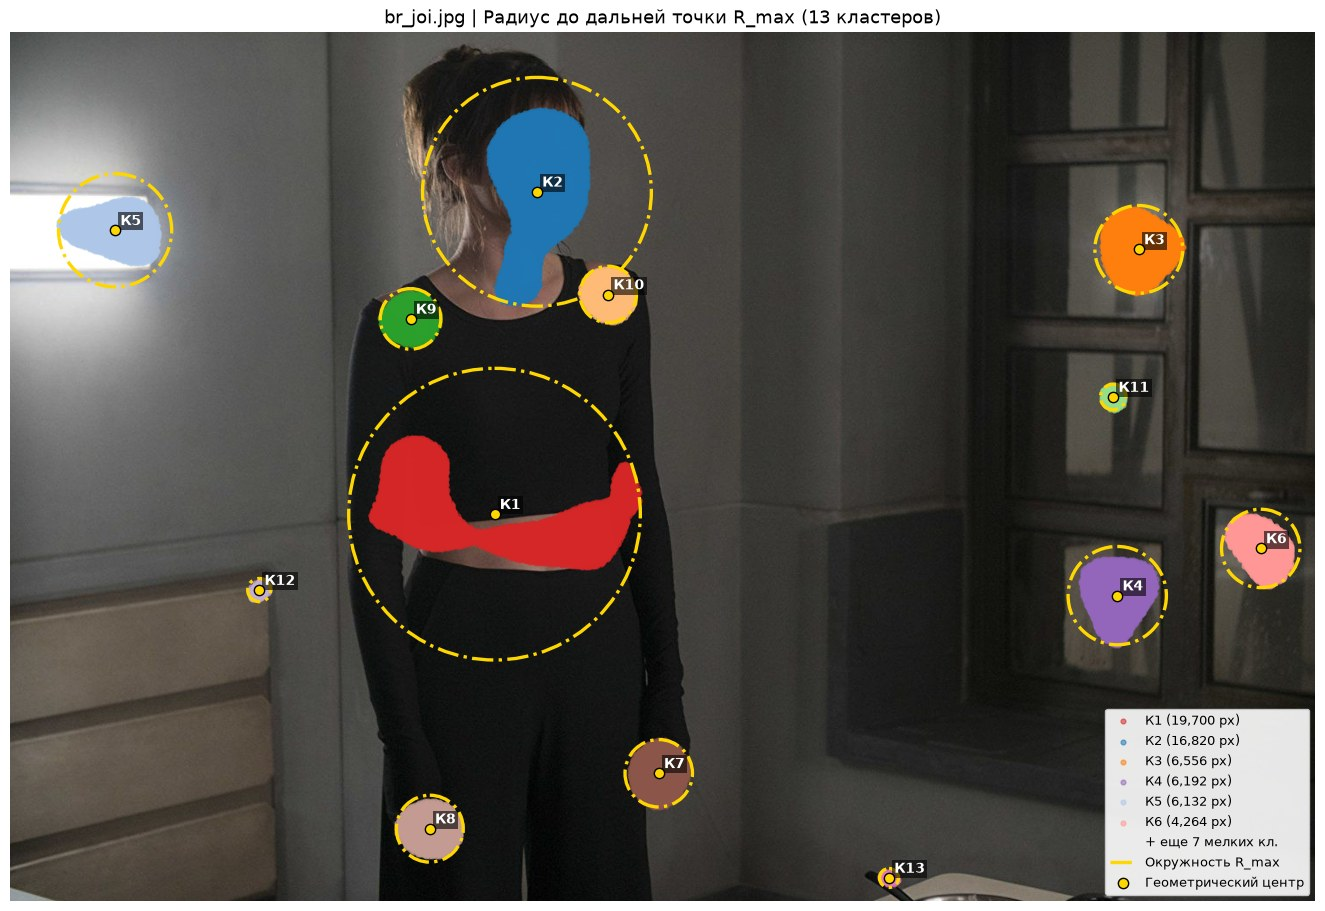


Размеры объектов для br_joi.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,19700,"(556.3, 554.0)",79.2,203.4,335.2,39.6,101.7,167.6,31.17,80.04,131.90
1,К2,16820,"(605.1, 183.5)",73.2,126.0,262.9,36.6,63.0,131.4,28.80,49.59,103.46
2,К3,6556,"(1296.7, 249.7)",45.7,65.2,100.8,22.8,32.6,50.4,17.98,25.66,39.69
3,К4,6192,"(1271.9, 647.6)",44.4,64.6,113.0,22.2,32.3,56.5,17.47,25.44,44.46
4,К5,6132,"(120.3, 227.7)",44.2,68.3,130.0,22.1,34.1,65.0,17.39,26.87,51.17
5,К6,4264,"(1436.8, 593.3)",36.8,54.5,90.1,18.4,27.3,45.0,14.50,21.46,35.45
6,К7,4004,"(745.0, 851.7)",35.7,50.8,77.5,17.9,25.4,38.7,14.05,19.98,30.50
7,К8,3772,"(481.9, 915.4)",34.7,49.3,76.9,17.3,24.7,38.4,13.64,19.41,30.25
8,К9,3160,"(459.8, 329.6)",31.7,45.1,69.6,15.9,22.5,34.8,12.48,17.75,27.39
9,К10,3020,"(687.0, 301.5)",31.0,44.0,65.0,15.5,22.0,32.5,12.20,17.30,25.56



Изображение: landscape.jpg | Разрешение: 740x415 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



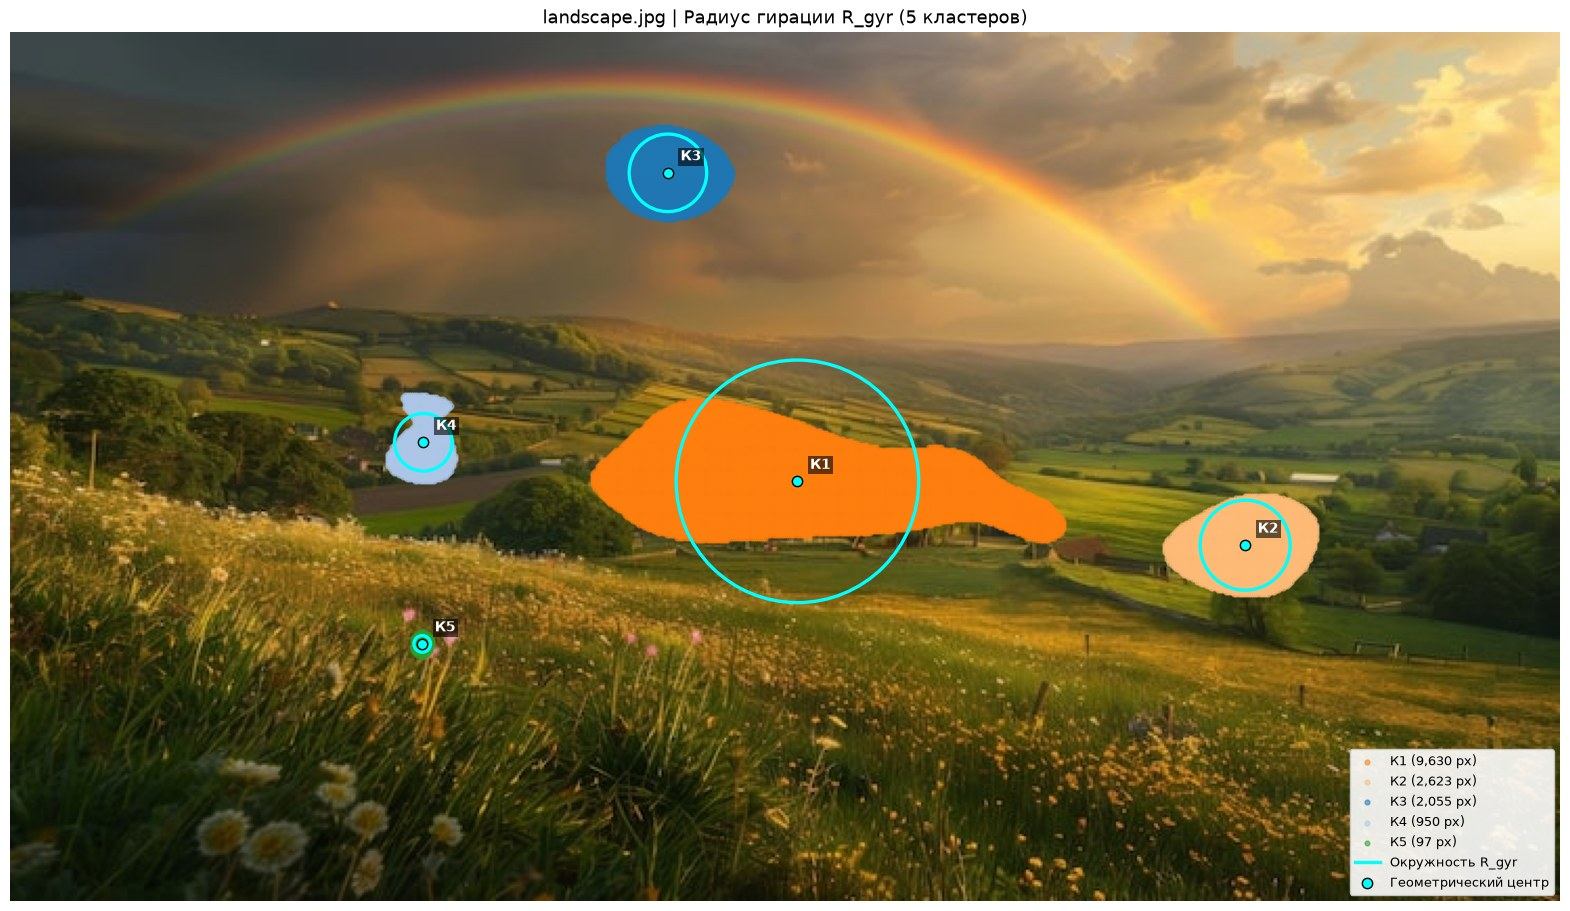

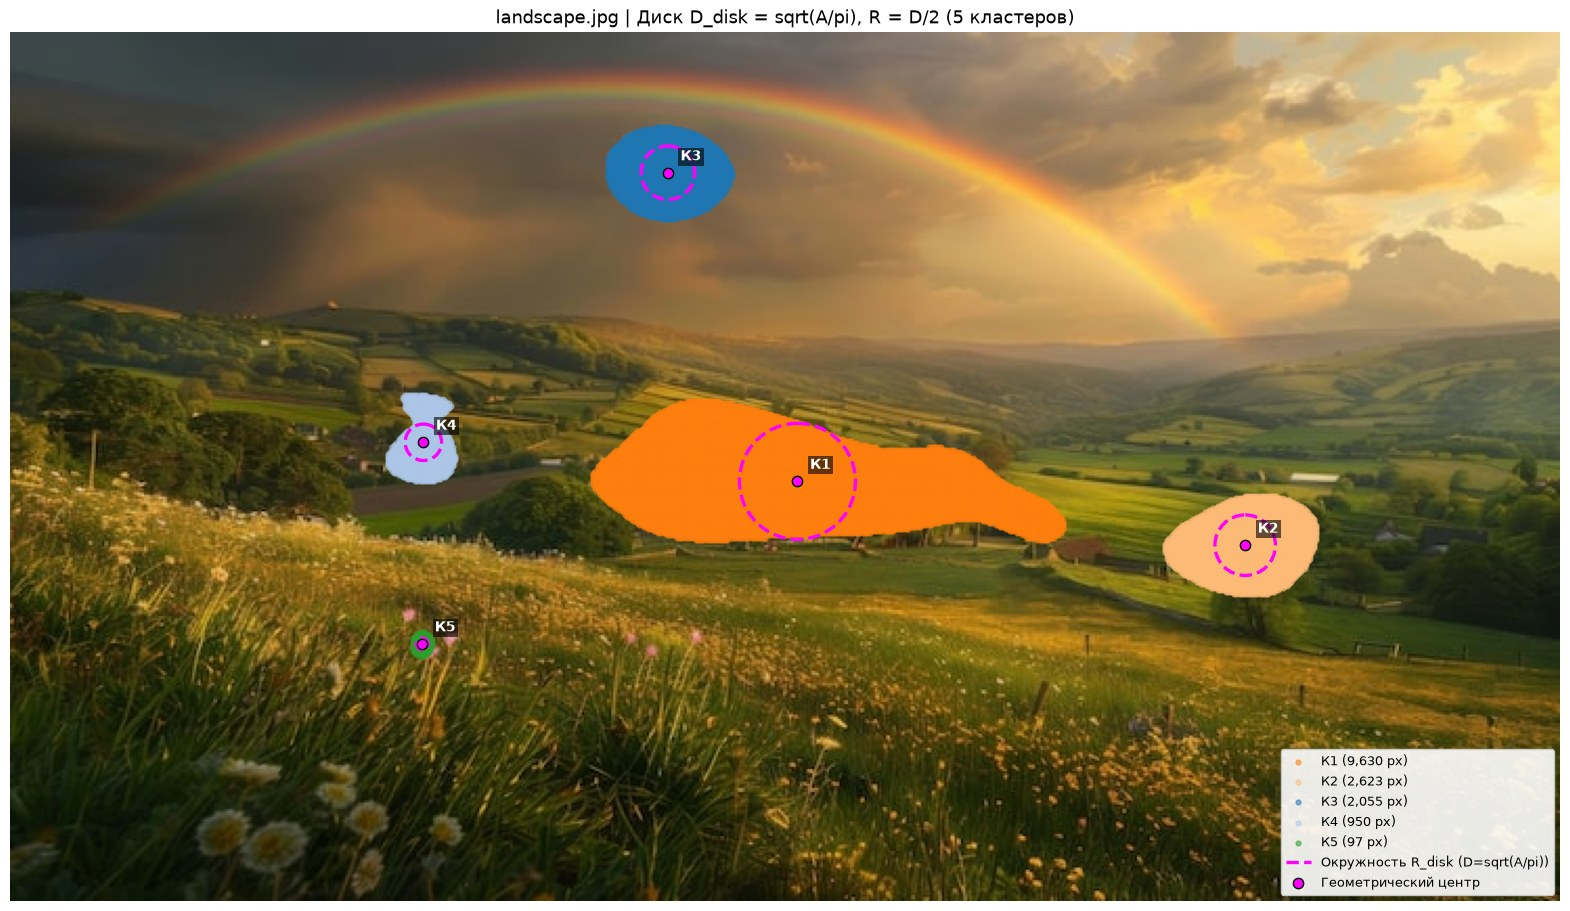

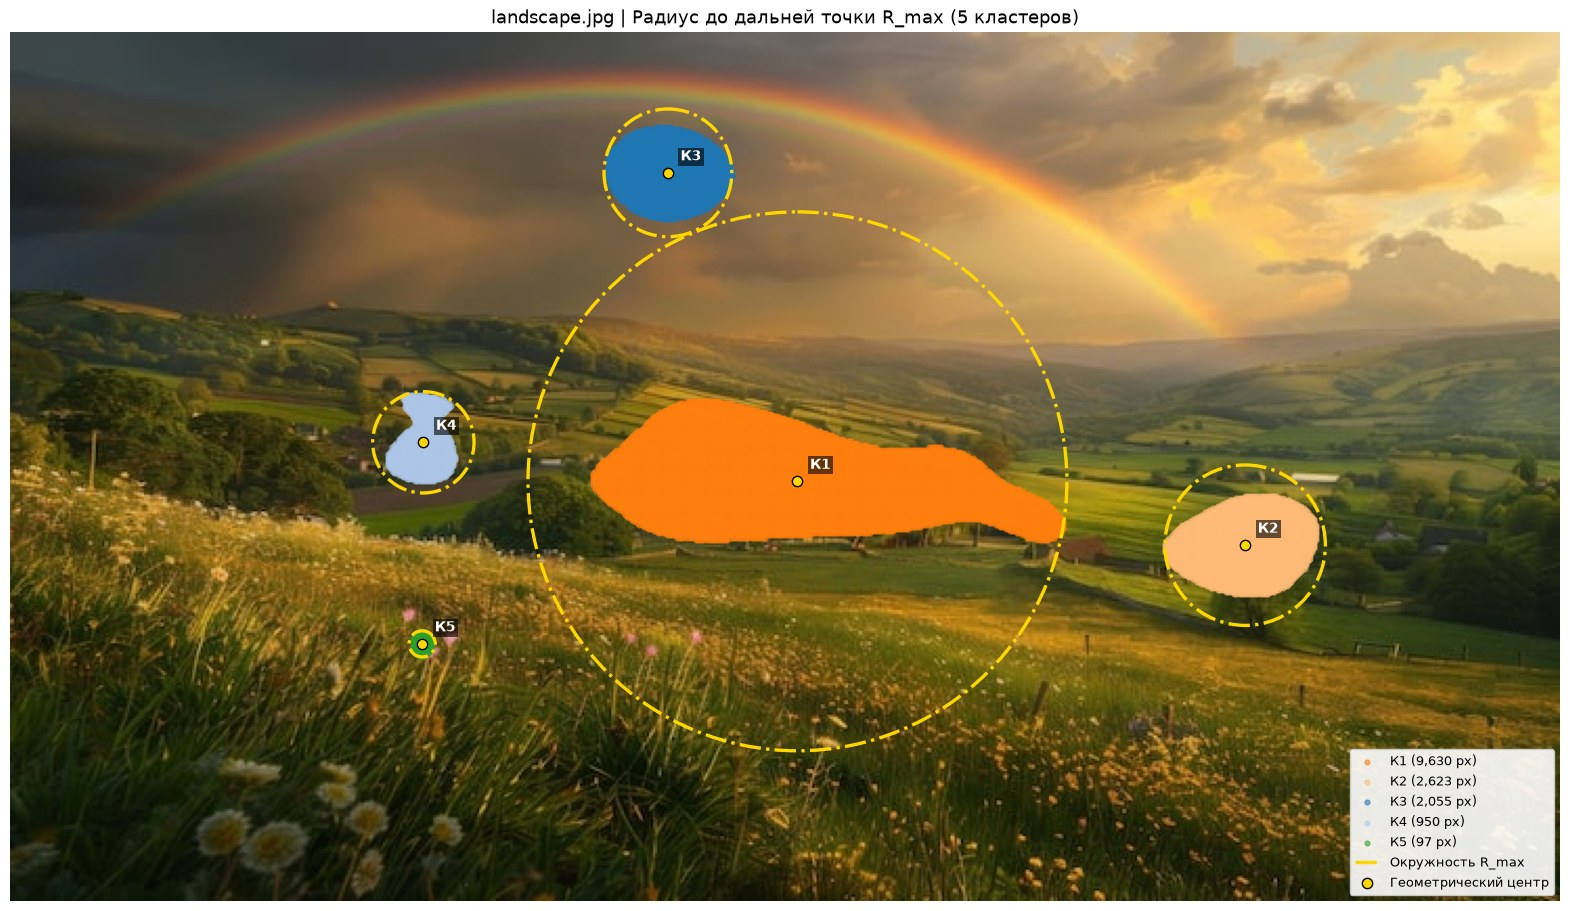


Размеры объектов для landscape.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,9630,"(375.4, 214.2)",55.4,115.8,257.3,27.7,57.9,128.6,44.17,92.37,205.24
1,К2,2623,"(589.1, 244.6)",28.9,43.0,76.6,14.4,21.5,38.3,23.05,34.27,61.09
2,К3,2055,"(313.6, 66.9)",25.6,37.0,61.0,12.8,18.5,30.5,20.40,29.52,48.65
3,К4,950,"(196.8, 195.5)",17.4,27.5,48.4,8.7,13.8,24.2,13.87,21.94,38.60
4,К5,97,"(196.3, 291.8)",5.6,7.9,12.5,2.8,4.0,6.2,4.43,6.33,9.96



Изображение: photo_flower.jpg | Разрешение: 736x913 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



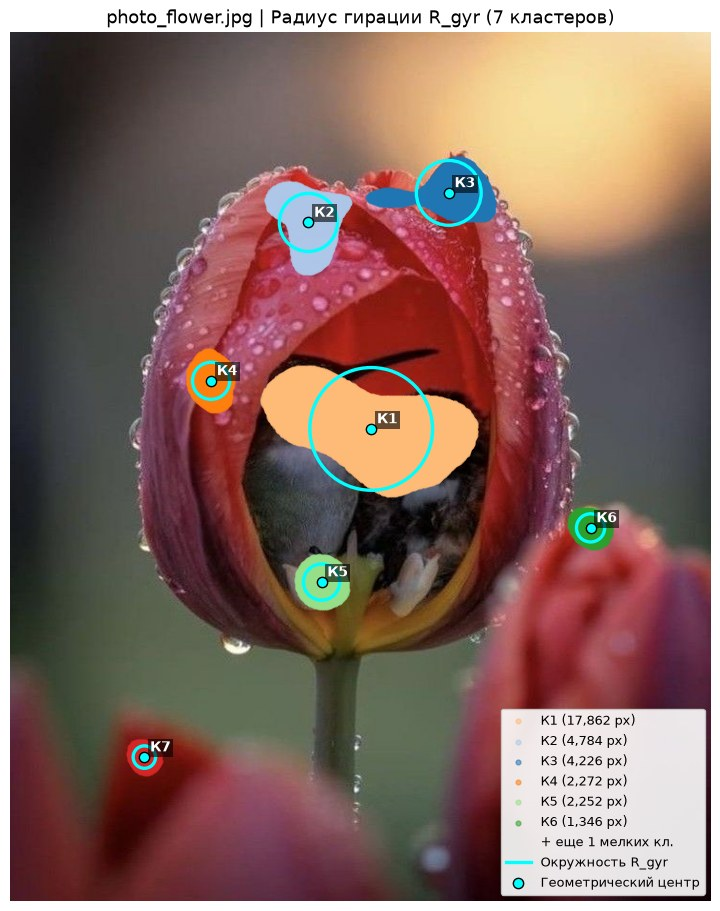

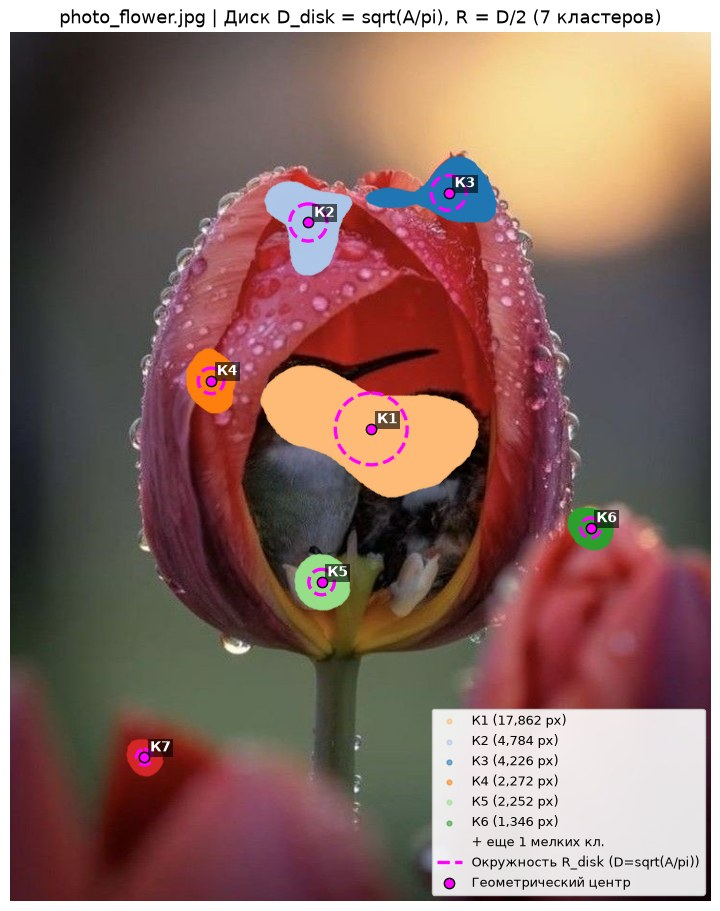

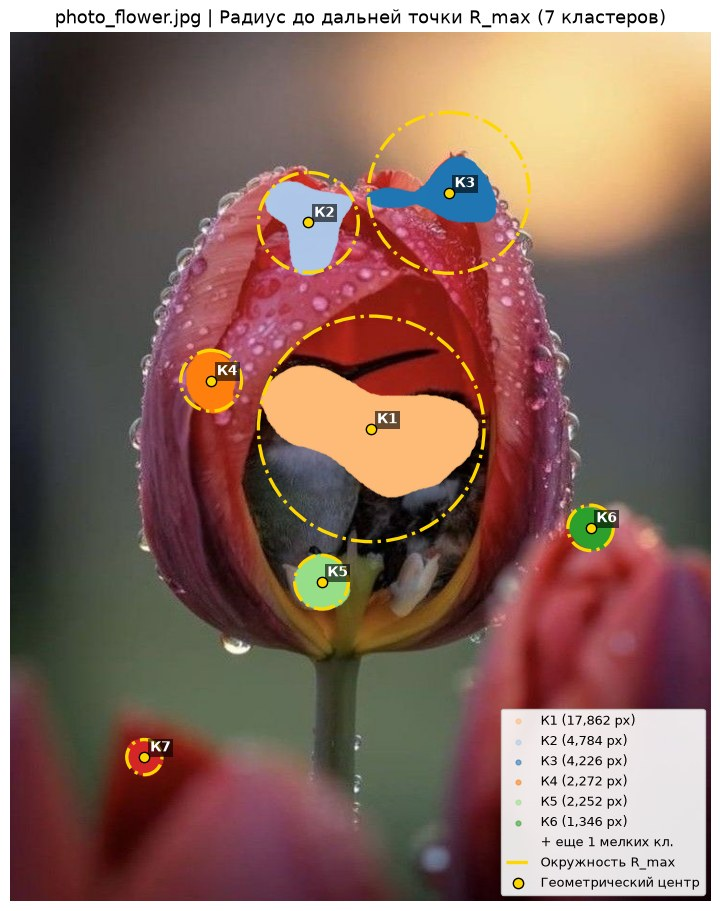


Размеры объектов для photo_flower.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,17862,"(378.9, 416.7)",75.4,128.9,236.9,37.7,64.4,118.5,60.48,103.38,190.04
1,К2,4784,"(312.9, 199.9)",39.0,61.0,104.9,19.5,30.5,52.5,31.30,48.90,84.15
2,К3,4226,"(460.3, 168.8)",36.7,68.1,168.9,18.3,34.0,84.4,29.42,54.61,135.44
3,К4,2272,"(210.7, 366.2)",26.9,39.0,63.8,13.4,19.5,31.9,21.57,31.27,51.21
4,К5,2252,"(326.7, 577.5)",26.8,38.0,56.4,13.4,19.0,28.2,21.48,30.45,45.23
5,К6,1346,"(609.2, 520.6)",20.7,29.6,47.7,10.3,14.8,23.8,16.60,23.76,38.25
6,К7,858,"(140.6, 761.3)",16.5,23.6,36.9,8.3,11.8,18.5,13.26,18.90,29.61



Изображение: photo_woman.jpg | Разрешение: 736x1098 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



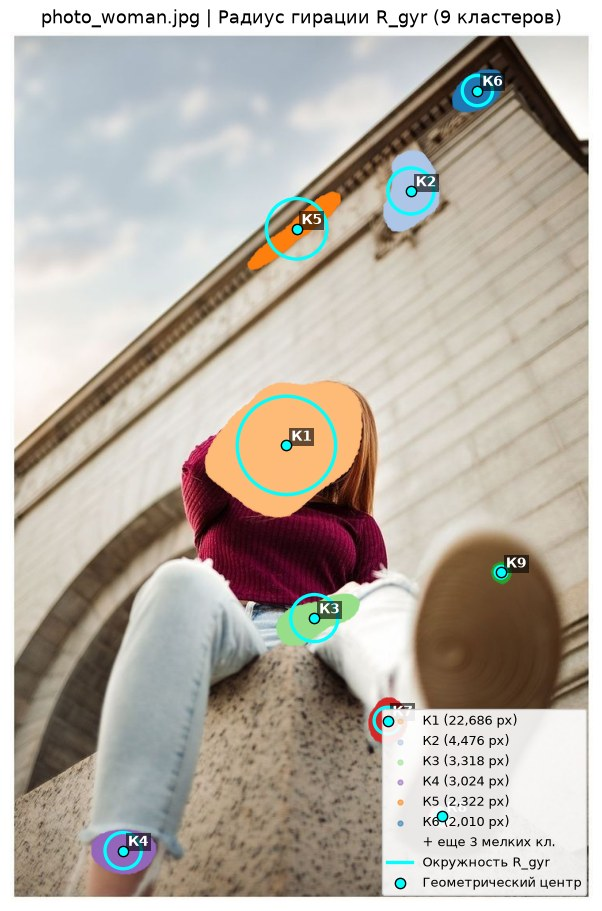

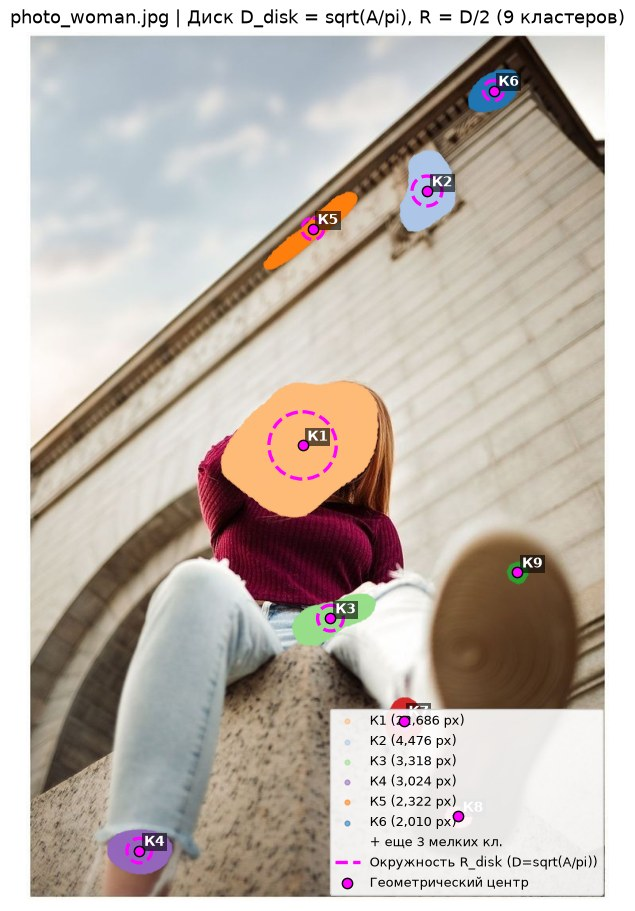

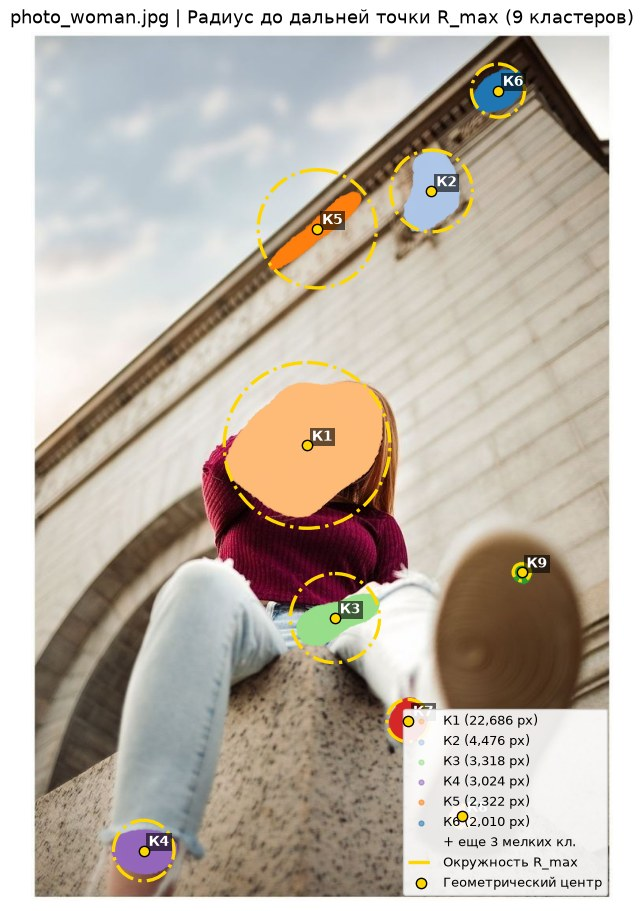


Размеры объектов для photo_woman.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,22686,"(348.6, 522.1)",85.0,124.2,209.3,42.5,62.1,104.6,68.16,99.66,167.85
1,К2,4476,"(505.8, 200.7)",37.7,58.1,103.2,18.9,29.1,51.6,30.28,46.61,82.76
2,К3,3318,"(383.9, 740.2)",32.5,59.5,112.5,16.2,29.7,56.3,26.07,47.69,90.27
3,К4,3024,"(142.4, 1033.8)",31.0,45.8,76.5,15.5,22.9,38.2,24.89,36.77,61.34
4,К5,2322,"(361.5, 248.5)",27.2,76.4,149.2,13.6,38.2,74.6,21.81,61.32,119.66
5,К6,2010,"(589.8, 73.9)",25.3,38.2,67.1,12.6,19.1,33.5,20.29,30.65,53.81
6,К7,1749,"(476.3, 869.6)",23.6,33.8,53.5,11.8,16.9,26.8,18.93,27.10,42.94
7,К8,480,"(544.7, 990.8)",12.4,17.9,28.9,6.2,9.0,14.4,9.91,14.40,23.16
8,К9,342,"(619.8, 682.3)",10.4,14.7,21.5,5.2,7.4,10.8,8.37,11.83,17.26



Изображение: Rosenblatt.jpg | Разрешение: 387x429 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



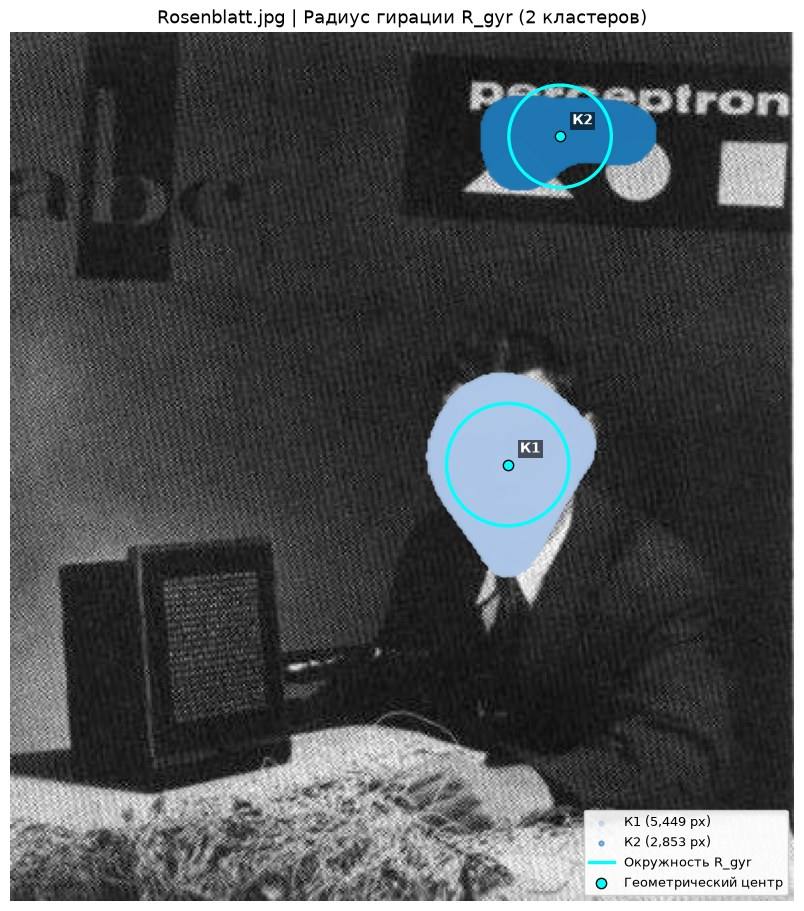

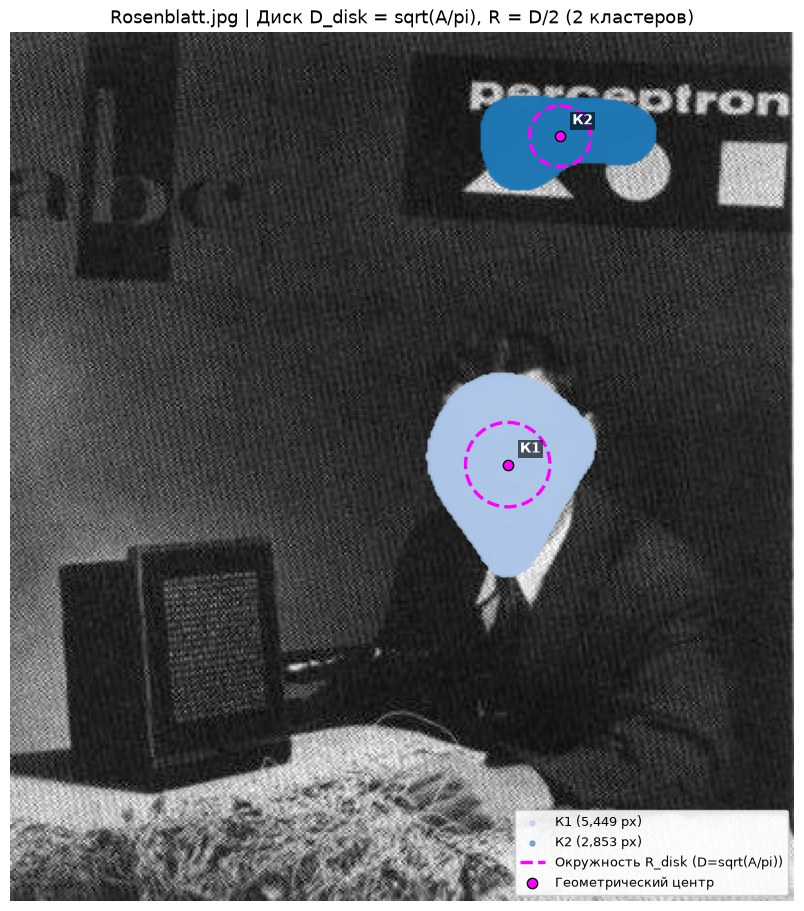

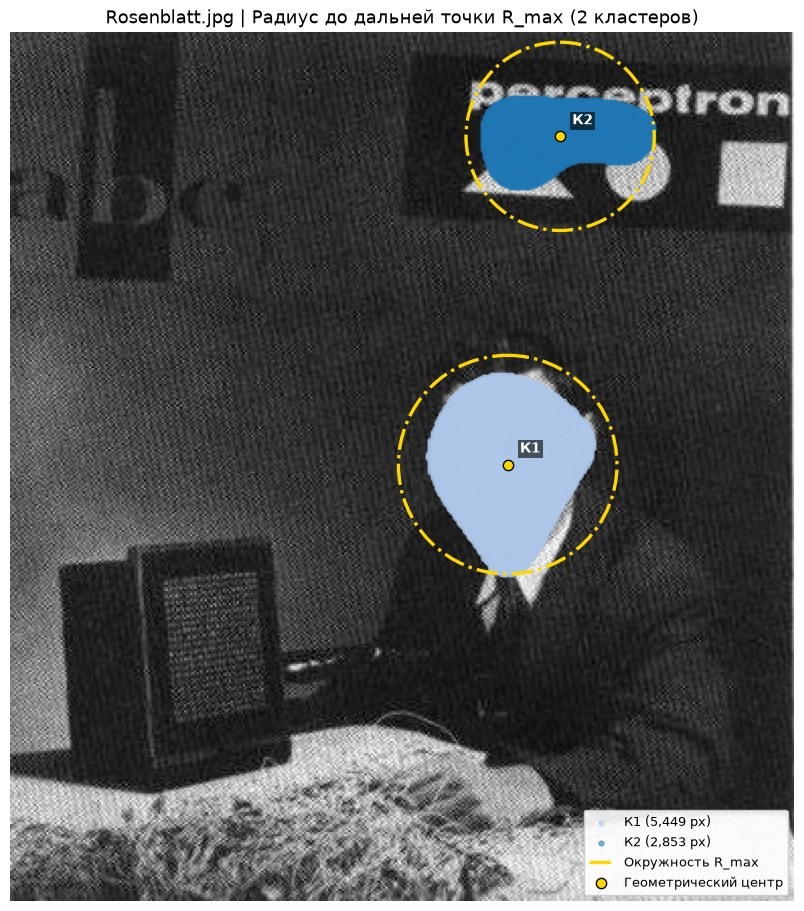


Размеры объектов для Rosenblatt.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,5449,"(245.1, 213.2)",41.6,60.4,107.9,20.8,30.2,53.9,63.53,92.15,164.56
1,К2,2853,"(271.0, 51.2)",30.1,50.6,92.9,15.1,25.3,46.4,45.97,77.14,141.70



Изображение: tiger.jpg | Разрешение: 736x1104 px | Модель: UNISAL (оригинал)
Параметры: топ-5.0% внимания, eps=4.0 px, геометрический центр



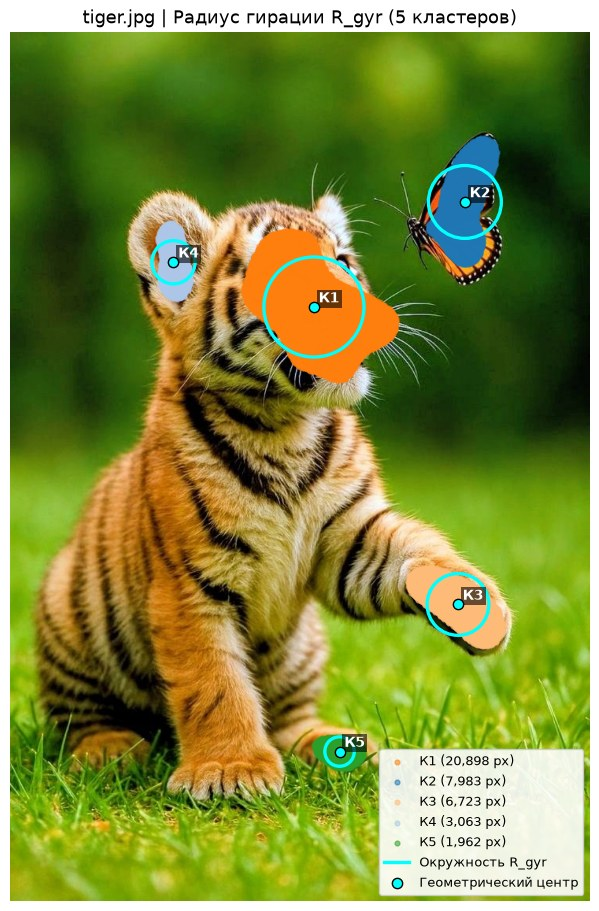

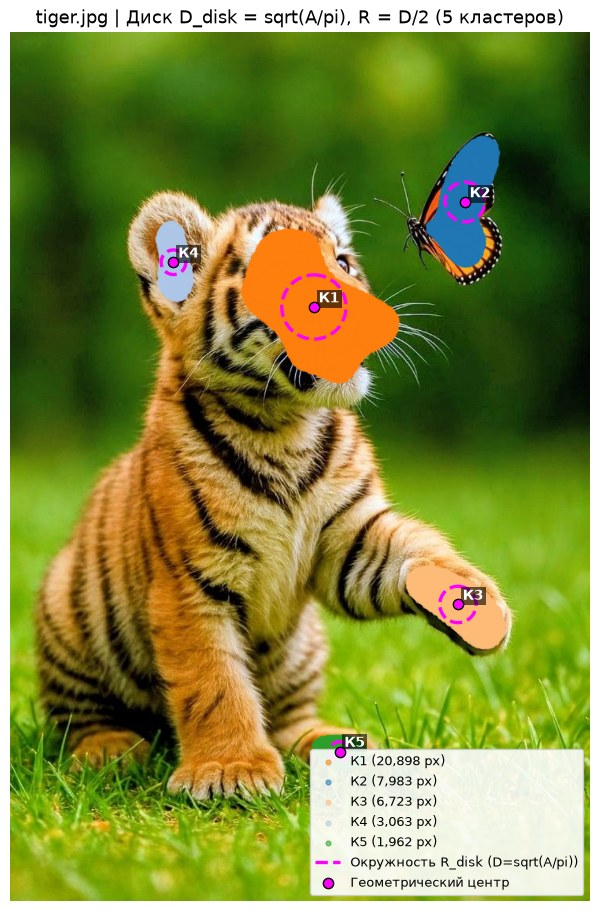

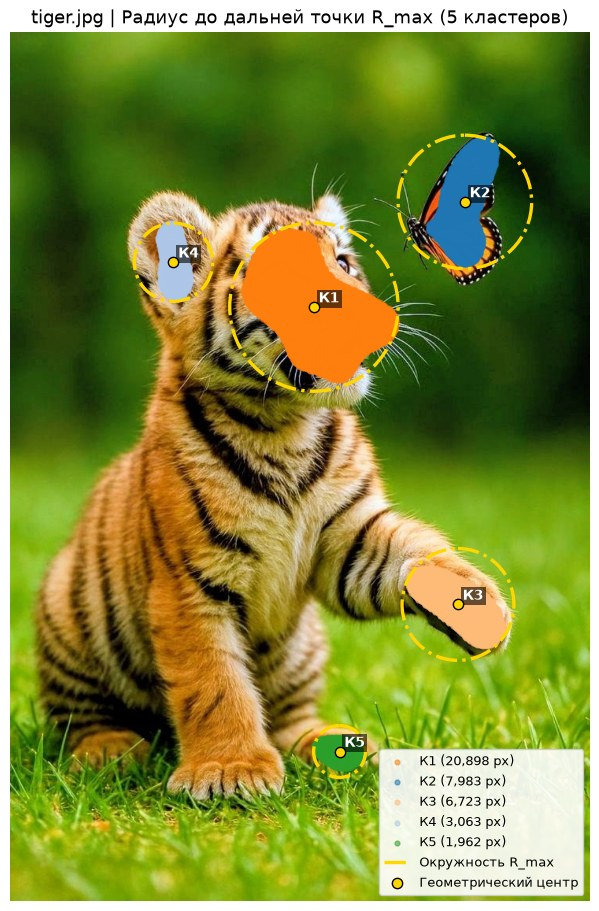


Размеры объектов для tiger.jpg:


,Объект,Площадь (px),"Центр (x, y)",D_disk (px),D_gyr (px),D_max (px),R_disk (px),R_gyr (px),R_max (px),Угол D_disk (мрад),Угол D_gyr (мрад),Угол D_max (мрад)
0,К1,20898,"(385.5, 349.2)",81.6,127.1,213.9,40.8,63.5,107.0,65.42,101.92,171.58
1,К2,7983,"(577.2, 215.7)",50.4,92.6,169.6,25.2,46.3,84.8,40.43,74.25,136.03
2,К3,6723,"(568.4, 726.9)",46.3,78.4,142.0,23.1,39.2,71.0,37.11,62.90,113.93
3,К4,3063,"(207.1, 292.3)",31.2,54.8,99.4,15.6,27.4,49.7,25.05,43.98,79.73
4,К5,1962,"(418.0, 913.7)",25.0,37.4,65.9,12.5,18.7,32.9,20.04,29.98,52.82


In [3]:
for img_path in EXAMPLE_IMAGES:
    run_experiment_3(img_path)
